# WattRota — Elektrik fiyat tahmini

## 1. Araştırma sorusu ve bilgi zamanı

**Geçmiş fiyatlar ve takvim bilgileriyle kurulan Random Forest, basit fiyat tekrarından daha düşük 48 saatlik tahmin hatası verebilir mi?**

Plan 00.00'da başlar ve 72 saati kapsar. Normal piyasa işleyişinde ilk günün 24 saatlik fiyatları önceki gün açıklanmış kabul edilir. Yalnızca sonraki iki günün, yani 48 saatin fiyatı tahmin edilir. Bilinen ilk gün hata hesabına katılmaz.

EPİAŞ'ın [normal GÖP sürecinde](https://www.epias.com.tr/gun-oncesi-piyasasi/surecler/) ertesi gün fiyatları önceki gün kesinleşir. Arşiv CSV'leri yayın zamanına göre sürümlenmiş kayıtlar içermediğinden bu çalışma normal açıklanma takvimini varsayan geriye dönük değerlendirmedir; teknik gecikme ve sonradan veri düzeltmelerini yeniden kurmaz.

In [1]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

proje = Path.cwd()
if not (proje / "src").is_dir():
    proje = proje.parent
sys.path.insert(0, str(proje / "src"))
from fiyat_tahmini import elektrik_fiyatlarini_oku, ozellikleri_hazirla, hata_ozeti

klasor = proje / "data/results/fiyat_tahmini"
bilgi = json.loads((klasor / "deney_bilgisi.json").read_text(encoding="utf-8"))
secim = json.loads((klasor / "model_secimi.json").read_text(encoding="utf-8"))
for ad, beklenen in bilgi["dosya_sha256"].items():
    assert hashlib.sha256((proje / ad).read_bytes()).hexdigest() == beklenen, ad
fiyat = elektrik_fiyatlarini_oku(proje)
tahminler = pd.read_csv(klasor / "saatlik_tahminler.csv", parse_dates=["karar_zamani", "tarih_saat"])
ozet = hata_ozeti(tahminler)
pd.testing.assert_frame_equal(ozet, pd.read_csv(klasor / "hata_ozeti.csv"), check_dtype=False)
model_etiketleri = {secim["basit_model"]: "Basit yöntem", secim["ml_model"]: "Random Forest"}
model_renkleri = {secim["basit_model"]: "#e9a23b", secim["ml_model"]: "#2878b5"}


## 2. Zaman sırası ve model seçimi

- 2024 verisi ilk eğitim geçmişini sağlar.
- 2025'te 52 pazartesi başlangıcında tahmin yapılır. Üç basit yöntem ve iki eğitim penceresi karşılaştırılır; seçim MAE ile yapılır.
- En iyi basit yöntem ve en iyi Random Forest penceresi sabitlenir. 2026'da 44 pazartesi başlangıcında bu iki yöntem değerlendirilir; seçim 2026 sonucuna göre değiştirilmez.
- Her karar tarihinde eğitim yalnızca o tarihte bilinen fiyatları içerir. Açıklanmış ilk gün fiyatları da bilgi kümesindedir. Haftalar ilerledikçe önceki haftalarda açıklanmış fiyatlarla model yeniden eğitilir.

2026 verileri keşifsel analizde daha önce görüldü. Bu nedenle burada bütünüyle hiç görülmemiş bir kör test iddiası yerine, karar zamanındaki bilgiyle yapılan zamansal değerlendirme raporlanır. Hedef saatler salı ve çarşambadır; sonuç bütün hafta günleri için genellenmez.

In [2]:
for bolum, df in tahminler.groupby("bolum", sort=False):
    print(bolum, "— karar sayısı:", df["karar_zamani"].nunique(),
          "— yöntemler:", ", ".join(df["model"].unique()))
assert (tahminler["tarih_saat"] >= tahminler["karar_zamani"] + pd.Timedelta(hours=24)).all()
assert (tahminler["tarih_saat"] < tahminler["karar_zamani"] + pd.Timedelta(hours=72)).all()
assert not tahminler.duplicated(["bolum", "model", "tarih_saat"]).any()

izler = pd.read_csv(klasor / "egitim_izleri.csv")
ml_izleri = izler[izler["model"].str.startswith("random_forest")].copy()
for alan in ["bilinen_son_saat", "egitim_son_saat", "en_yeni_gecmis_ozellik_saati"]:
    ml_izleri[alan] = pd.to_datetime(ml_izleri[alan])
assert (ml_izleri["egitim_son_saat"] <= ml_izleri["bilinen_son_saat"]).all()
assert (ml_izleri["en_yeni_gecmis_ozellik_saati"] <= ml_izleri["bilinen_son_saat"]).all()
print("Eğitim ve tahmin özellikleri, karar anındaki açıklanmış fiyat sınırını aşmıyor.")
print("Seçilen basit yöntem:", secim["basit_model"])
print("Seçilen ML yöntemi:", secim["ml_model"])

dogrulama_2025 — karar sayısı: 52 — yöntemler: son_yayinlanan_gun, onceki_hafta, son_dort_hafta, random_forest_180gun, random_forest_365gun
ileri_donem_2026 — karar sayısı: 44 — yöntemler: son_yayinlanan_gun, random_forest_365gun
Eğitim ve tahmin özellikleri, karar anındaki açıklanmış fiyat sınırını aşmıyor.
Seçilen basit yöntem: son_yayinlanan_gun
Seçilen ML yöntemi: random_forest_365gun


## 3. Yöntemler ve özellikler

| Yöntem | Mantık |
|---|---|
| Son yayımlanan gün | Bilinen ilk günün 24 saatlik profili iki güne tekrar edilir. Üçüncü gün için henüz bilinmeyen ikinci gün kullanılmaz. |
| Önceki hafta | Hedef saatin yedi gün önceki fiyatı kullanılır. |
| Son dört hafta | Hedef saatin önceki dört haftadaki fiyatlarının ortalaması alınır. |
| Random Forest | Geçmiş fiyat ve takvim özellikleriyle 80 karar ağacının tahminleri birleştirilir. Son 180 veya 365 günlük eğitim penceresi 2025'te karşılaştırılır. |

Random Forest girdileri: saat, haftanın günü, ay, yıl; 48/72/168/336/504/672 saat önceki fiyatlar; 48 saat geciktirilmiş serinin 24 saatlik ortalaması, minimumu, maksimumu ve 168 saatlik ortalaması.

48 saat gecikme özellikle seçilmiştir: son hedef saatindeki en yeni fiyat girdisi bile açıklanmış ilk günün son saatini aşmaz. Gelecek fiyatları değiştirme/silme testiyle tahminlerin bundan etkilenmediği kontrol edilir.

In [3]:
ornek_karar = pd.Timestamp("2026-10-05")
bilinen = fiyat.loc[fiyat.index < ornek_karar + pd.Timedelta(hours=24)]
x = ozellikleri_hazirla(bilinen, ornek_karar + pd.Timedelta(hours=71))
x.loc[ornek_karar + pd.Timedelta(hours=24):].head()

,saat,haftanin_gunu,ay,yil,ptf_gecikme_48,ptf_gecikme_72,ptf_gecikme_168,ptf_gecikme_336,ptf_gecikme_504,ptf_gecikme_672,son_24_ortalama,son_24_en_dusuk,son_24_en_yuksek,son_168_ortalama
2026-10-06 00:00:00,0,1,10,2026,2088.89,1500.01,2599.38,3697.07,3873.99,2893.99,1603.580417,238.0,2999.0,2130.594286
2026-10-06 01:00:00,1,1,10,2026,1330.01,1200.00,2127.99,3025.67,2999.99,2475.00,1608.997500,238.0,2999.0,2128.094345
2026-10-06 02:00:00,2,1,10,2026,1699.99,999.99,1933.05,2800.00,2777.77,1999.97,1638.164167,238.0,2999.0,2129.209583
2026-10-06 03:00:00,3,1,10,2026,1500.01,950.01,1300.00,3023.61,2099.98,1999.97,1661.080833,238.0,2999.0,2128.019226
2026-10-06 04:00:00,4,1,10,2026,1499.99,1200.00,1556.00,2500.00,2099.97,1282.00,1673.580417,238.0,2999.0,2126.531131


## 4. Tahmin hataları

MAE, mutlak hatanın ortalamasını; RMSE, büyük hatalara daha fazla ağırlık veren hata büyüklüğünü gösterir. İkisinin birimi TL/MWh'dir ve düşük değer daha iyidir. Ortalama işaretli hata pozitifse model ortalamada yüksek tahmin yapmıştır. Sıfır fiyatlar bulunduğundan MAPE kullanılmaz.

In [4]:
ozet.round(2)

,bolum,model,saat_sayisi,karar_sayisi,MAE_TL_MWh,RMSE_TL_MWh,ortalama_isaretli_hata
0,dogrulama_2025,son_yayinlanan_gun,2496,52,332.18,520.59,-37.72
1,dogrulama_2025,onceki_hafta,2496,52,372.34,578.36,-8.69
2,dogrulama_2025,son_dort_hafta,2496,52,338.40,502.14,-24.23
3,dogrulama_2025,random_forest_180gun,2496,52,340.53,489.56,-82.70
4,dogrulama_2025,random_forest_365gun,2496,52,333.50,477.90,-77.24
5,ileri_donem_2026,son_yayinlanan_gun,2112,44,556.24,806.27,-123.70
6,ileri_donem_2026,random_forest_365gun,2112,44,528.52,727.86,-105.00


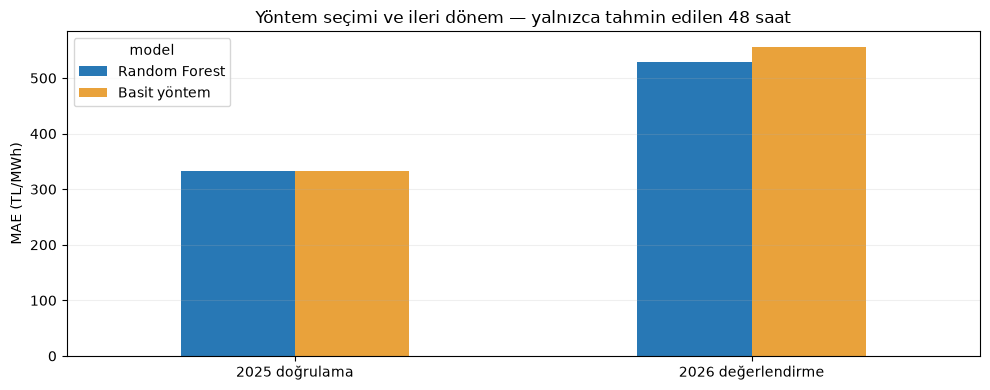

,bolum,model,ufuk_gun,saat_sayisi,MAE_TL_MWh,RMSE_TL_MWh
0,dogrulama_2025,onceki_hafta,2,1248,420.05,651.69
1,dogrulama_2025,onceki_hafta,3,1248,324.63,494.26
2,dogrulama_2025,random_forest_180gun,2,1248,371.24,537.03
3,dogrulama_2025,random_forest_180gun,3,1248,309.82,436.97
4,dogrulama_2025,random_forest_365gun,2,1248,365.25,523.96
5,dogrulama_2025,random_forest_365gun,3,1248,301.74,426.90
6,dogrulama_2025,son_dort_hafta,2,1248,364.41,543.03
7,dogrulama_2025,son_dort_hafta,3,1248,312.39,457.62
8,dogrulama_2025,son_yayinlanan_gun,2,1248,319.09,504.74
9,dogrulama_2025,son_yayinlanan_gun,3,1248,345.27,535.98


In [5]:
secilenler = ozet[ozet["model"].isin([secim["basit_model"], secim["ml_model"]])]
grafik = secilenler.pivot(index="bolum", columns="model", values="MAE_TL_MWh")
gosterim = grafik.rename(columns=model_etiketleri, index={"dogrulama_2025": "2025 doğrulama", "ileri_donem_2026": "2026 değerlendirme"})
ax = gosterim.plot.bar(figsize=(10, 4), rot=0, color=[model_renkleri[ad] for ad in grafik.columns])
ax.set_ylabel("MAE (TL/MWh)")
ax.set_xlabel("")
ax.set_title("Yöntem seçimi ve ileri dönem — yalnızca tahmin edilen 48 saat")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

pd.read_csv(klasor / "ufuk_hatalari.csv").round(2)

## 5. Döneme göre hata ve örnek tahmin

Aylık değerler yalnızca haftalık kararların 48 saatlik hedef pencerelerini kapsar; ayın bütün saatlerini kapsamaz. Tek bir başarılı haftanın genel başarı diye sunulmasını önlemek için dönemler ayrı gösterilir.

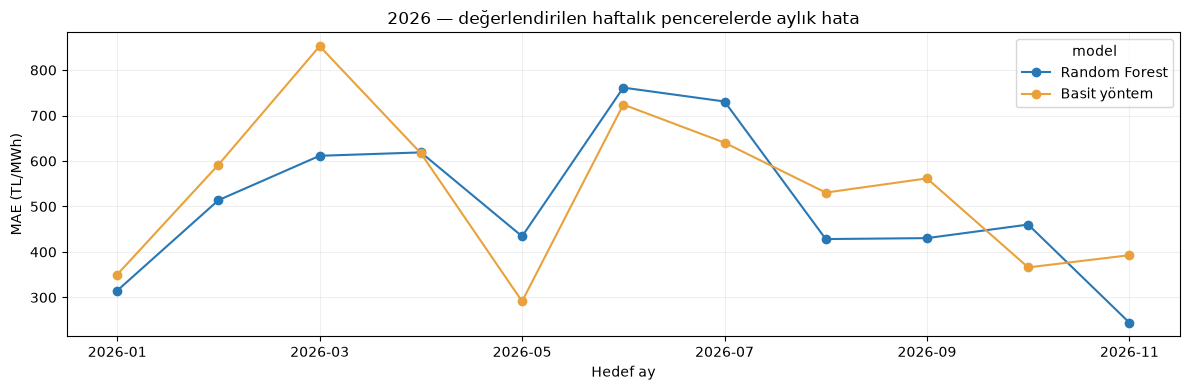

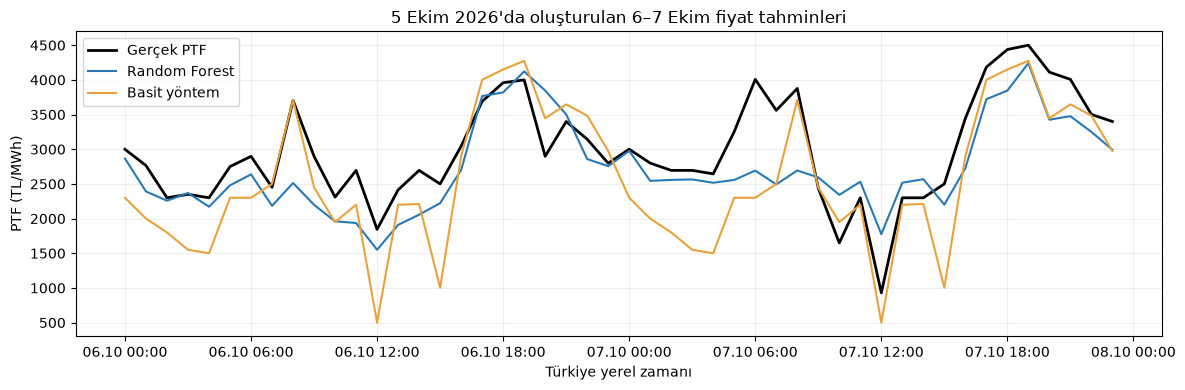

In [6]:
ileri = tahminler[tahminler["bolum"] == "ileri_donem_2026"].copy()
ileri["ay"] = ileri["tarih_saat"].dt.to_period("M").astype(str)
ileri["mutlak_hata"] = (ileri["tahmin"] - ileri["gercek"]).abs()
aylik = ileri.groupby(["ay", "model"])["mutlak_hata"].mean().unstack()
ax = aylik.rename(columns=model_etiketleri).plot(figsize=(12, 4), marker="o", color=[model_renkleri[ad] for ad in aylik.columns])
ax.set_ylabel("MAE (TL/MWh)")
ax.set_xlabel("Hedef ay")
ax.set_title("2026 — değerlendirilen haftalık pencerelerde aylık hata")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

ornek = ileri[ileri["karar_zamani"] == ornek_karar]
fig, ax = plt.subplots(figsize=(12, 4))
gercek = ornek.drop_duplicates("tarih_saat")
ax.plot(gercek["tarih_saat"], gercek["gercek"], color="black", label="Gerçek PTF", linewidth=2)
for ad, df in ornek.groupby("model"):
    ax.plot(df["tarih_saat"], df["tahmin"], label=model_etiketleri[ad], color=model_renkleri[ad])
ax.set_ylabel("PTF (TL/MWh)")
ax.set_xlabel("Türkiye yerel zamanı")
ax.set_title("5 Ekim 2026'da oluşturulan 6–7 Ekim fiyat tahminleri")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Bulguların yorumu

Makine öğrenmesinin daha karmaşık olması daha düşük hata garantisi değildir. Aşağıdaki hesap seçilmiş iki yöntemin 2026 hata farkını gösterir. Fiyat hatası ile üretim planının maliyeti farklı ölçütlerdir; karar maliyeti ayrı deneyde değerlendirilir.

In [7]:
donem = ozet[ozet["bolum"] == "ileri_donem_2026"].set_index("model")
basit_mae = donem.loc[secim["basit_model"], "MAE_TL_MWh"]
ml_mae = donem.loc[secim["ml_model"], "MAE_TL_MWh"]
print(f"Basit yöntem MAE: {basit_mae:.2f} TL/MWh")
print(f"Makine öğrenmesi MAE: {ml_mae:.2f} TL/MWh")
print(f"ML'nin MAE farkı (basit - ML): {basit_mae-ml_mae:.2f} TL/MWh")
print("Yorum:", "Bu dönemde ML'nin ortalama mutlak hatası daha düşük."
      if ml_mae < basit_mae else "Bu dönemde basit yöntem daha iyi veya aynı; ML üstünlüğü gösterilemedi.")

Basit yöntem MAE: 556.24 TL/MWh
Makine öğrenmesi MAE: 528.52 TL/MWh
ML'nin MAE farkı (basit - ML): 27.72 TL/MWh
Yorum: Bu dönemde ML'nin ortalama mutlak hatası daha düşük.


Yöntem ve veri sözlüğü: `docs/fiyat-tahmini-yontemi.md`. Model ve özellik üretimi `src/fiyat_tahmini.py` dosyasındadır. Girdi kaynağı ham EPİAŞ CSV'leridir; tahmin, hata ve eğitim zamanı kayıtları `data/results/fiyat_tahmini` klasöründedir.